# can we make a function S(R) that compliments Hz(R) ?

In [1]:
import matplotlib.pyplot as plt
import numpy as np

## symmetric case

In [13]:
x = np.linspace(-50, 50, 1000)
dx = x[1]-x[0]
print(dx)

rmin = 5

R = np.sqrt(rmin**2 + x**2)

0.10010010010010006


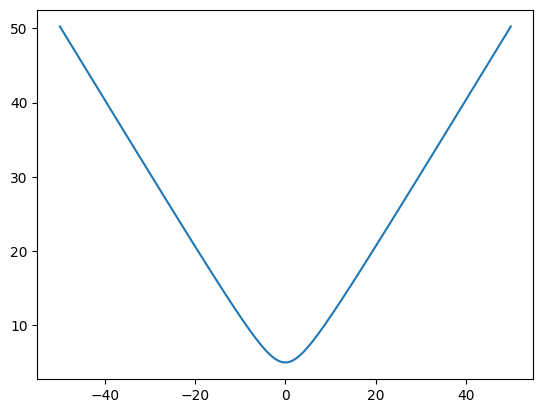

In [14]:
plt.figure()
plt.plot(x, R)

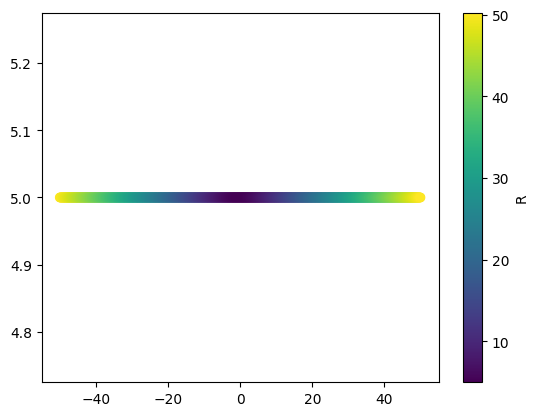

In [15]:
plt.figure()
pcm=plt.scatter(x, np.ones_like(x)*rmin, c=R)
plt.colorbar(pcm, label='R')

C:\Users\au646858\AppData\Local\Temp\ipykernel_21064\2754225844.py:16: RuntimeWarning: invalid value encountered in sqrt
  p = np.nan_to_num(np.sqrt(R_edge2**2 - rmin**2) - np.sqrt(R_edge1**2 - rmin**2))


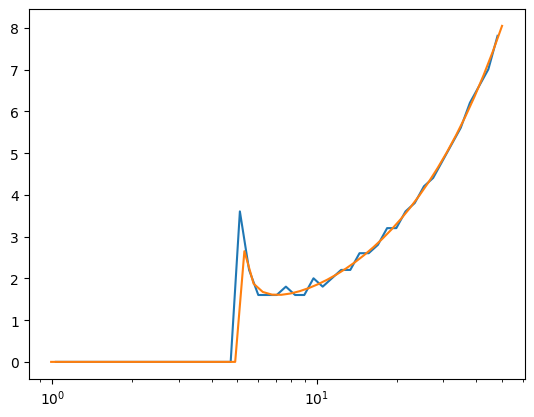

In [17]:
rbins = np.geomspace(0.99,50, 50)
dR_alpha = np.sqrt(rbins[1]/rbins[0])
R_edge1 = rbins/dR_alpha
R_edge2 = rbins*dR_alpha

n,bins = np.histogram(R, bins=rbins, weights=np.diff(x, prepend=0))

assert np.all(rbins==bins), "bins equals bins?"

mid = 0.5*(rbins[1:]+rbins[:-1])

plt.figure()
plt.plot(mid, n)


p = np.nan_to_num(np.sqrt(R_edge2**2 - rmin**2) - np.sqrt(R_edge1**2 - rmin**2))

plt.plot(rbins, 2*p)
plt.xscale('log')

## asymmetric case

In [18]:
x = np.linspace(-25, 50, 1000)
dx = x[1]-x[0]
print(dx)

rmin = 5

R = np.sqrt(rmin**2 + x**2)

0.07507507507507682


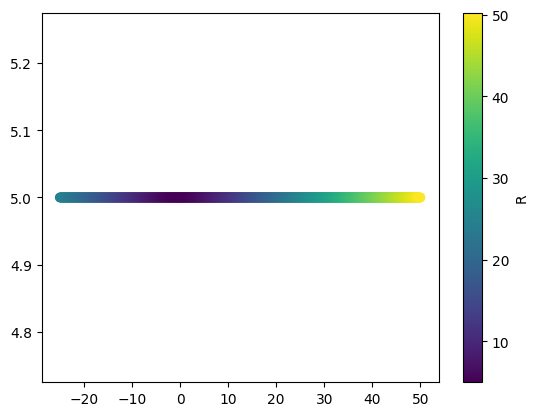

In [19]:
plt.figure()
pcm=plt.scatter(x, np.ones_like(x)*rmin, c=R)
plt.colorbar(pcm, label='R')

In [25]:
def box(x, xmin, xmax):
    y = np.ones_like(x)
    y[x<xmin]=0
    y[x>xmax]=0
    return y

def box_filter(r, r_min, r_par_max):
    r_max = np.sqrt(r_min**2 + r_par_max**2)
    y = np.ones_like(r)
    y[r<r_min]=0
    y[r>r_max]=0
    if np.all(y==0):
         ir = np.searchsorted(r, r_min)
         y[ir] = 0.5
         y[ir+1] = 0.5
    y *= np.sign(r_par_max)
    return y

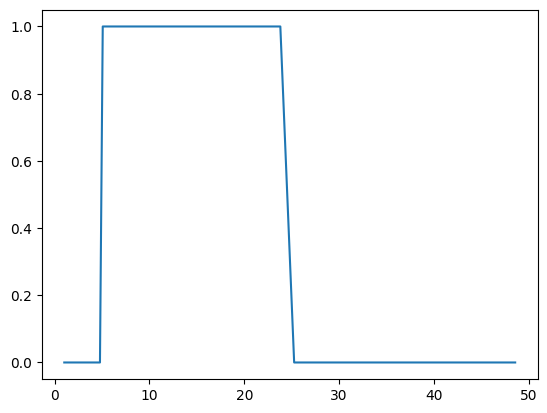

In [26]:
plt.figure()
plt.plot(mid, box(mid, 5, 25))

C:\Users\au646858\AppData\Local\Temp\ipykernel_21064\3188389542.py:20: RuntimeWarning: invalid value encountered in sqrt
  p = np.nan_to_num(np.sqrt(R_edge2**2 - rmin**2) - np.sqrt(R_edge1**2 - rmin**2))*interval


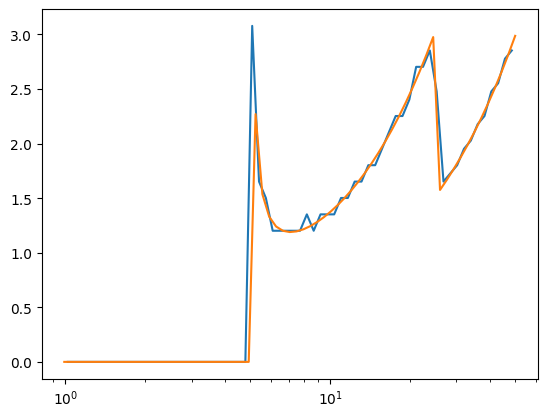

In [31]:
rbins = np.geomspace(0.99,50, 67)

dR_alpha = np.sqrt(rbins[1]/rbins[0])
R_edge1 = rbins/dR_alpha
R_edge2 = rbins*dR_alpha

n,bins = np.histogram(R, bins=rbins, weights=np.clip(np.diff(x, prepend=0), 0, None))

assert np.all(rbins==bins), "bins equals bins?"

mid = 0.5*(rbins[1:]+rbins[:-1])

plt.figure()
plt.plot(mid, n)

dR = np.gradient(mid)

#p = (box(mid, rmin, 25)+box(mid, rmin, 50))*mid*dR/np.sqrt(mid**2 - rmin**2)
interval = box_filter(rbins, np.abs(rmin), 50)-box_filter(rbins, np.abs(rmin), -25)
p = np.nan_to_num(np.sqrt(R_edge2**2 - rmin**2) - np.sqrt(R_edge1**2 - rmin**2))*interval

# p = box(mid, 5, 50)*mid*dR/np.sqrt(mid**2 - rmin**2)
# p = 2*mid*dR/np.sqrt(mid**2 - rmin**2)

plt.plot(rbins, p)
plt.xscale('log')

# Hells ya we can!
but wait, we still need to check the off centered case...

## off center case

In [32]:
x = np.linspace(25, 50, 1000)
dx = x[1]-x[0]
print(dx)

rmin = 5

R = np.sqrt(rmin**2 + x**2)

0.025025025025026792


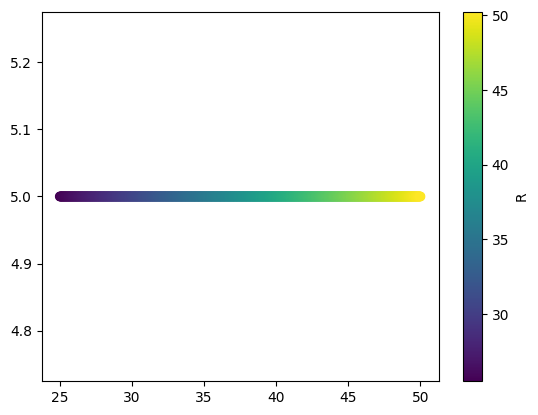

In [33]:
plt.figure()
pcm=plt.scatter(x, np.ones_like(x)*rmin, c=R)
plt.colorbar(pcm, label='R')

In [34]:
def box(x, xmin, xmax):
    y = np.ones_like(x)
    y[x<xmin]=0
    y[x>xmax]=0
    return y

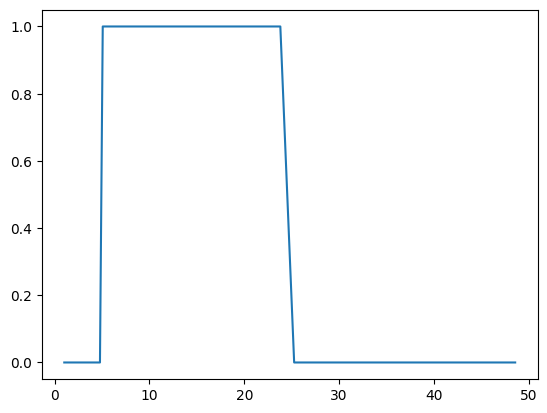

In [35]:
plt.figure()
plt.plot(mid, box(mid, 5, 25))

C:\Users\au646858\AppData\Local\Temp\ipykernel_21064\3297562956.py:20: RuntimeWarning: invalid value encountered in sqrt
  p = np.nan_to_num(np.sqrt(R_edge2**2 - rmin**2) - np.sqrt(R_edge1**2 - rmin**2))*interval


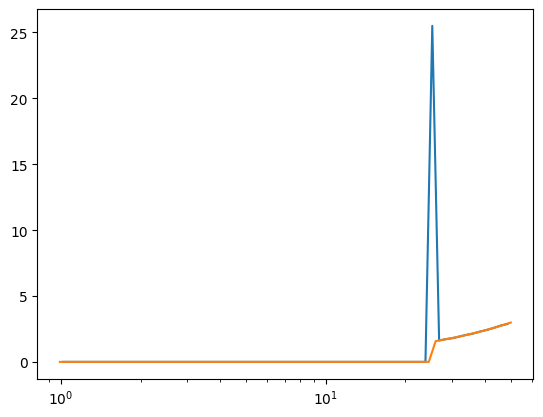

In [37]:
rbins = np.geomspace(0.99,50, 67)

dR_alpha = np.sqrt(rbins[1]/rbins[0])
R_edge1 = rbins/dR_alpha
R_edge2 = rbins*dR_alpha

n,bins = np.histogram(R, bins=rbins, weights=np.clip(np.diff(x, prepend=0), 0, None))

assert np.all(rbins==bins), "bins equals bins?"

mid = 0.5*(rbins[1:]+rbins[:-1])

plt.figure()
plt.plot(mid, n)

dR = np.gradient(mid)

#p = (box(mid, rmin, 25)+box(mid, rmin, 50))*mid*dR/np.sqrt(mid**2 - rmin**2)
interval = box_filter(rbins, np.abs(rmin), 50)-box_filter(rbins, np.abs(rmin), 25)
p = np.nan_to_num(np.sqrt(R_edge2**2 - rmin**2) - np.sqrt(R_edge1**2 - rmin**2))*interval

plt.plot(rbins, p)
plt.xscale('log')

In [38]:
np.nansum(p)

26.519685110359912

ok, the total length check, checks out within 1%... so maybe its fine

In [39]:
from em1d.experiment import Loop

def perp_distance_to_line(x,y, line_points):
	((x1,y1), (x2,y2)) = line_points
	numerator = np.abs((x2-x1)*(y1-y) - (x1-x)*(y2-y1))
	denominator = np.sqrt((x2-x1)**2 + (y2-y1)**2)
	return numerator / denominator

def box_filter(r, r_min, r_par_max):
    r_max = np.sqrt(r_min**2 + r_par_max**2)
    y = np.ones_like(r)
    y[r<r_min]=0
    y[r>r_max]=0
    if np.all(y==0):
         ir = np.searchsorted(r, r_min)
         y[ir-1] = 0.5
         y[ir] = 0.5
    y *= np.sign(r_par_max)
    return y

def getRz(P,Q):
    QP = Q-P
    mQP = np.linalg.norm(QP, axis=-1)
    cos_theta = QP[..., 0] / mQP
    sin_theta = QP[..., 1] / mQP

    Rz = np.zeros(QP.shape+(3,))

    Rz[..., 0,0] = cos_theta
    Rz[..., 1,1] = cos_theta
    Rz[..., 0,1] = sin_theta
    Rz[..., 1,0] = -sin_theta
    Rz[..., 2,2] = 1.
    
    return Rz, Rz.swapaxes(-1, -2)

# def s_of_r(loop: Loop, xyz, R):
#     dR = np.gradient(R)
    
#     s = np.zeros_like(R)

#     lp_xyz = loop.xyz - xyz[None, :]

#     plt.figure()
#     for i in range(len(loop)-1):
#         Rz,iRz = getRz(lp_xyz[i], lp_xyz[i+1])
#         p1 = np.einsum('...i,...i->...', Rz, lp_xyz[i])
#         p2 = np.einsum('...i,...i->...', Rz, lp_xyz[i+1])
#         # assert p1[1]==p2[1], "something in the rotation was messed up"
#         r_perp = p1[1]
#         interval = box_filter(R, np.abs(r_perp), p2[0])-box_filter(R, np.abs(r_perp), p1[0])
#         plt.plot(R, interval)
#         ds = np.nan_to_num(interval*R*dR/np.sqrt(R**2 - r_perp**2))
#         ds *= np.abs(p2[0]-p1[0])/np.abs(ds.sum())
#         s += np.sign(r_perp)*ds
#     plt.show()
#     return s     

def s_of_r(loop: Loop, xyz, R):
    dR_alpha = np.sqrt(R[1]/R[0])
    R_edge1 = R/dR_alpha
    R_edge2 = R*dR_alpha

    
    s = np.zeros_like(R)

    lp_xyz = loop.xyz - xyz[None, :]
    #rmax = lp_xyz.max_horizontal_distance()


    for i in range(len(loop)-1):
        Rz,iRz = getRz(lp_xyz[i], lp_xyz[i+1])
        p1 = np.einsum('...i,...i->...', Rz, lp_xyz[i])
        p2 = np.einsum('...i,...i->...', Rz, lp_xyz[i+1])
        r_perp = p1[1]
        ds = np.nan_to_num(np.sqrt(R_edge2**2 - r_perp**2) - np.sqrt(R_edge1**2 - r_perp**2))
        ds[np.abs(R_edge2)>np.linalg.norm(p2)] = 0.
        s += np.sign(r_perp)*ds
    return s   

In [15]:
def circle(r, line=0.02):
    circumference = 2*np.pi*r
    n_seg = round(circumference / line)
    theta = np.linspace(0., 2*np.pi, n_seg)
    x = r*np.cos(theta)
    y = r*np.sin(theta)
    z = np.zeros_like(x)
    return Loop(x,y,z)
    
lp = Loop.square(50)
#lp = Loop.circle(25, line=1)

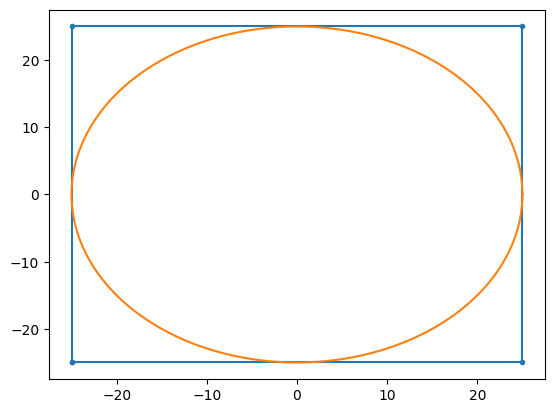

In [16]:
theta = np.linspace(0., 2*np.pi, 1001)
plt.figure()
plt.plot(lp.x, lp.y, '.-')
plt.plot(25*np.cos(theta), 25*np.sin(theta))

In [17]:
#r = np.geomspace(0.01, 100, 51)
r = np.linspace(1., 100, 201)
s = s_of_r(lp, np.array([0., 50, 0.]), r)

#s = lp.s_of_r(np.array([0,0,0]), r)

C:\Users\au646858\AppData\Local\Temp\ipykernel_16428\2999509289.py:76: RuntimeWarning: invalid value encountered in sqrt
  ds = np.nan_to_num(np.sqrt(R_edge2**2 - r_perp**2) - np.sqrt(R_edge1**2 - r_perp**2))


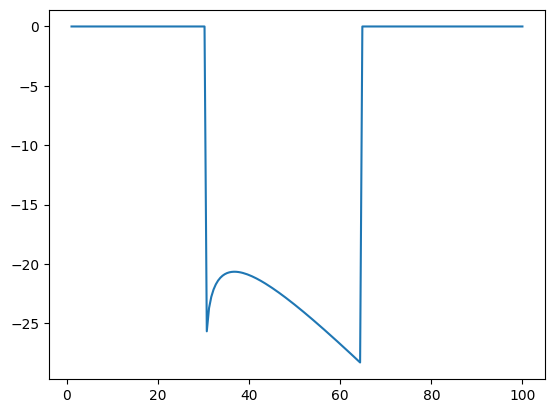

In [18]:
plt.figure()
plt.plot(r, s)

In [19]:
import matplotlib.pyplot as plt
import numpy as np

from em1d.experiment import Receiver, Loop

lp = Loop.square(25)

x = np.linspace(-50, 50, 101)
rx = Receiver(x=x, y=x)
rmax = lp.max_horizontal_distance(rx)
rmin = lp.min_horizontal_distance(rx)

In [21]:
r = np.geomspace(0.02, 120, 51)
s = s_of_r(lp, rx.xyz, r)

ValueError: operands could not be broadcast together with shapes (5,3) (1,101,101,3) 